# Tutorial 2: Analyze Stereo-se Mouse Olfactory Bulb dataset

In this tutorial, we demonstrate how to apply Redex to Stereo-seq spatial transcriptomics data. We use the Mouse Olfactory Bulb tissue section as an example.

The data should be placed under './5.Mouse_Olfactory/' in h5ad format.

## Loading packages

In [ ]:
# Installed package imports
import os
import pandas as pd
import scanpy as sc
import method
import Redex
from utils import clustering, plot_umap, plot_paga
import matplotlib.pyplot as plt

os.environ['R_HOME'] = '/home/user/anaconda3/envs/redex/lib/R'

## Configuration

In [2]:
DATA_ROOT   = './5.Mouse_Olfactory/'
RESULT_ROOT = './results/Mouse_Olfactory'
DATASETS = {'5.Mouse_Olfactory': 7,}

## Step 1: Gene Selection (Skip if the gene set already exists.)
Redex performs SVF selection module by computing the R_g score across multiple expression thresholds (25th, 50th, 75th percentiles) and merging the results.

In [3]:
for dataset in DATASETS:
    save_dir = os.path.join(RESULT_ROOT, dataset)
    gene_result_file = os.path.join(save_dir, 'three_top_rg-results_df.csv')

    if os.path.exists(gene_result_file):
        print(f"[Skip] Gene selection for {dataset} — {gene_result_file} already exists.")
        continue

    print(f"\n{'='*50}")
    print(f"Gene selection for {dataset}")
    print(f"{'='*50}")

    data_path = os.path.join(DATA_ROOT, dataset)
    os.makedirs(save_dir, exist_ok=True)

    adata = sc.read_h5ad(os.path.join(data_path, 'filtered_feature_bc_matrix.h5ad'))
    adata = method.preprocess_adata(adata, min_cells=20)
    neighbors = method.compute_neighbors(adata, k_neighbors=6)

    results_dict = {}
    for thre in [25, 50, 75]:
        gene_groups = method.compute_gene_groups(adata, exp_thre=thre, num_workers=1)
        W_gs = method.compute_weight_matrices(adata, neighbors, num_workers=1)
        results, R_g_values = method.compute_r_values(adata, W_gs, num_workers=1)
        results_dict[thre] = results

    results_df = method.merge_files_and_compute_max(results_dict)
    results_df.to_csv(os.path.join(save_dir, 'three_top_rg-results_df.csv'), index=False)
    print(f"Gene selection results saved to {save_dir}")
    


Gene selection for 5.Mouse_Olfactory


D:\Users\jtyu\新建文件夹\NEW MODEL WITH NEW GENE COMBINE\github test\method.py:18: RuntimeWarning: divide by zero encountered in divide
  scale = np.where(diff != 0, (feature_range[1] - feature_range[0]) / diff, 0)
Computing gene groups: 100%|███████████████████████████████████████████████████| 17956/17956 [00:09<00:00, 1800.25it/s]
D:\Users\jtyu\新建文件夹\NEW MODEL WITH NEW GENE COMBINE\github test\method.py:98: ImplicitModificationWarning: Trying to modify attribute `.var` of view, initializing view as actual.
  adata.var['L_g'] = adata.var.index.map(lambda x: results[x]['L_g'] if x in results else [])
Computing R values: 100%|████████████████████████████████████████████████████████| 17956/17956 [04:52<00:00, 61.45it/s]


 R_g =A_g * B_g * C_g 


Computing R values: 100%|████████████████████████████████████████████████████████| 17956/17956 [05:09<00:00, 57.94it/s]


 R_g =A_g * B_g * C_g 


Computing R values: 100%|████████████████████████████████████████████████████████| 17956/17956 [05:34<00:00, 53.64it/s]


 R_g =A_g * B_g * C_g 
Gene selection results saved to ./results/Mouse_Olfactory\5.Mouse_Olfactory


## Step 2: Model Training
After gene selection, we train the Redex model using the selected spatially variable genes.

In [4]:
dataset = '5.Mouse_Olfactory'
n_clusters = 7

data_path = os.path.join(DATA_ROOT, dataset)
gene_path = os.path.join(RESULT_ROOT, dataset)
save_dir  = os.path.join(RESULT_ROOT, dataset)
os.makedirs(save_dir, exist_ok=True)

# Load data
adata = sc.read_h5ad(os.path.join(data_path, 'filtered_feature_bc_matrix.h5ad'))
adata.var_names_make_unique()
adata.obsm["spatial"][:, 1] *= -1

# Train model
model = Redex.Redex(adata, dataset, gene_path)
adata = model.train()


 self.num_heads 6
 self.alpha 12
 self.self.beta 4
processed 5.Mouse_Olfactory our gene 3000
Begin to train ST data...


100%|████████████████████████████████████████████████████████████████████████████████| 600/600 [02:25<00:00,  4.11it/s]


Optimization finished for ST data!


## Step 3: Spatial Clustering
After model training, we apply mclust for spatial clustering with domain refinement.


In [5]:
clustering(adata, n_clusters, radius=50, method='mclust', refinement=True)

R[write to console]:                    __           __ 
   ____ ___  _____/ /_  _______/ /_
  / __ `__ \/ ___/ / / / / ___/ __/
 / / / / / / /__/ / /_/ (__  ) /_  
/_/ /_/ /_/\___/_/\__,_/____/\__/   version 6.0.0
Type 'citation("mclust")' for citing this R package in publications.



fitting ...
  |======================================================================| 100%


## Step 4: Visualization
Spatial domain plot (all domains)

In [6]:
plt.rcParams["figure.figsize"] = (8, 6)
sc.pl.spatial(adata, color='mclust', title=f'REDEX - {dataset}',
              spot_size=50, show=False,
              save=f'{dataset}_clustering_Redex.pdf')

unique_domains = adata.obs['mclust'].unique()
cmap = plt.cm.get_cmap('tab10', len(unique_domains))
plt.rcParams['svg.fonttype'] = 'none'
plt.rcParams['figure.dpi'] = 300

for i, domain in enumerate(unique_domains):
    adata.obs['highlight'] = (adata.obs['mclust'] == domain).astype(str)
    palette = {'True': cmap(i), 'False': '#D3D3D3'}

    plt.rcParams["figure.figsize"] = (5, 5)
    sc.pl.spatial(adata, img_key="hires", color='highlight',
                  palette=palette, title=f'Domain: {domain}',
                  spot_size=50, show=False, frameon=False, legend_loc=None,
                  save=f"{dataset}_{domain}_spatial_highlight.pdf")
    del adata.obs['highlight']
    

D:\Users\jtyu\software\mytemp\3\ipykernel_12588\2186773894.py:7: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.
  cmap = plt.cm.get_cmap('tab10', len(unique_domains))


## Step 5: UMAP and PAGA

D:\Users\jtyu\software\Anaconda\envs\GraphST\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
D:\Users\jtyu\software\Anaconda\envs\GraphST\lib\site-packages\scanpy\plotting\_tools\scatterplots.py:394: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


Saved: ./results/Mouse_Olfactory\5.Mouse_Olfactory\5.Mouse_Olfactory_umap.pdf


<Figure size 900x900 with 0 Axes>

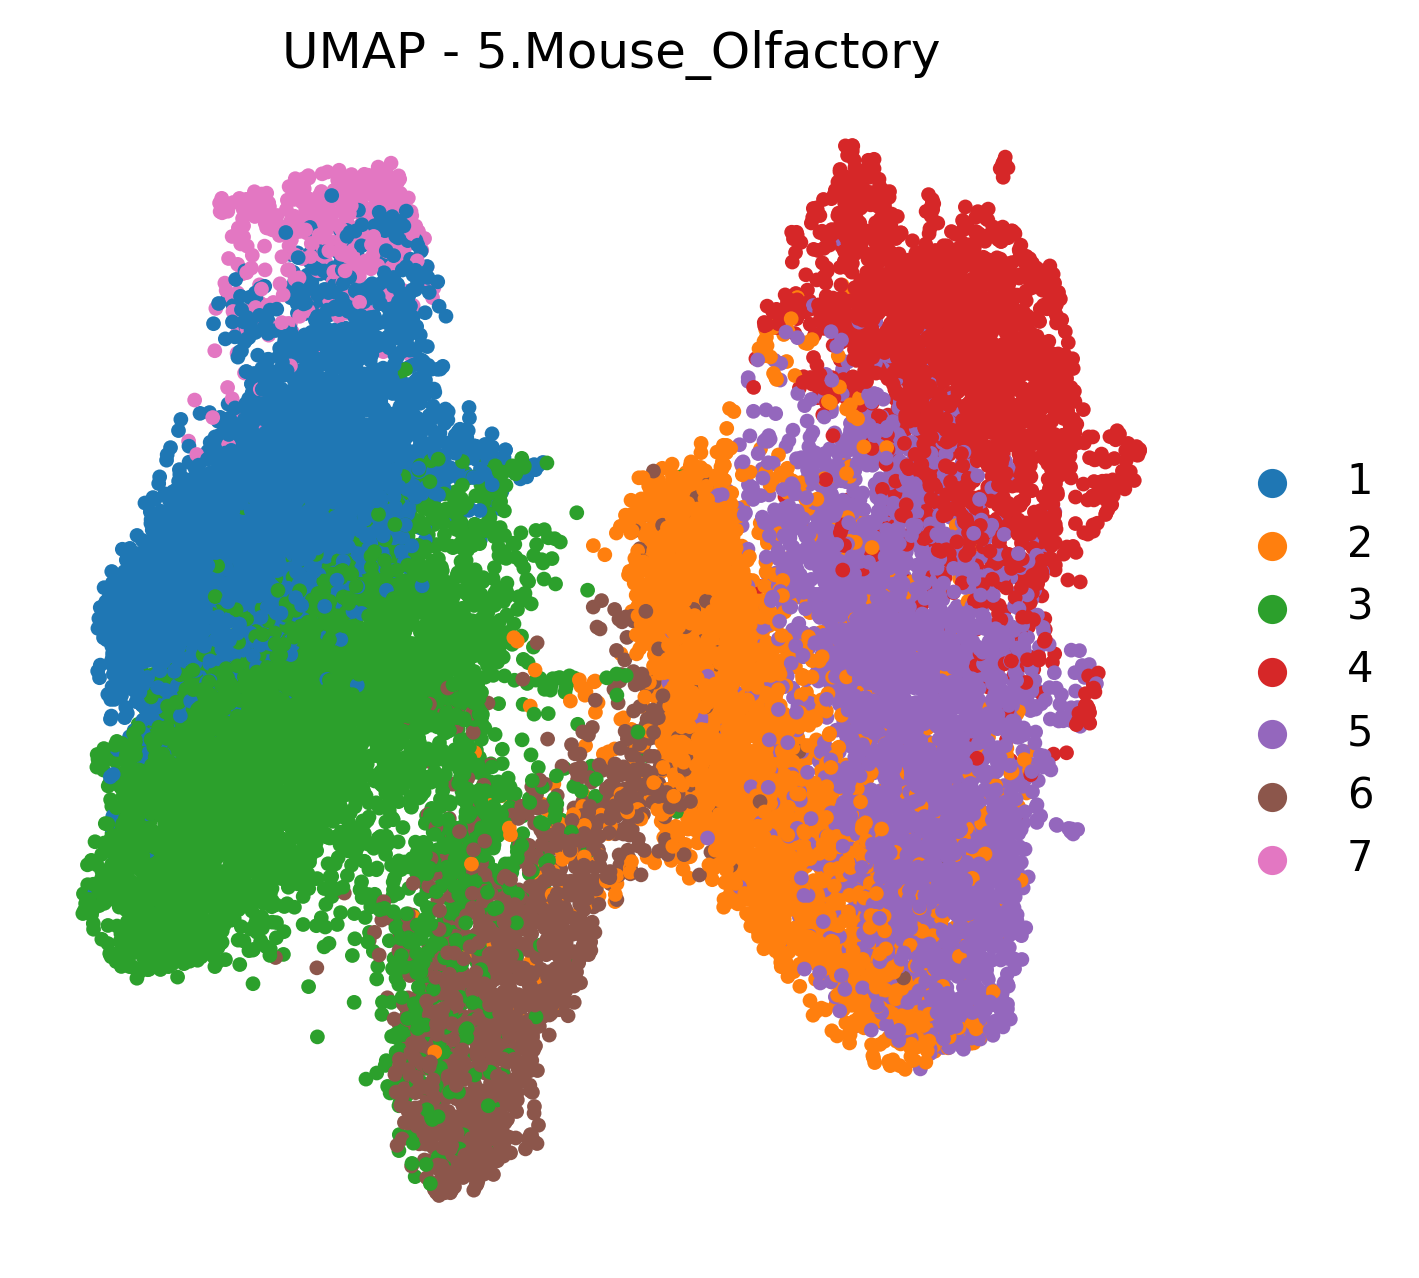

Saved: ./results/Mouse_Olfactory\5.Mouse_Olfactory\5.Mouse_Olfactory_paga.pdf


<Figure size 900x900 with 0 Axes>

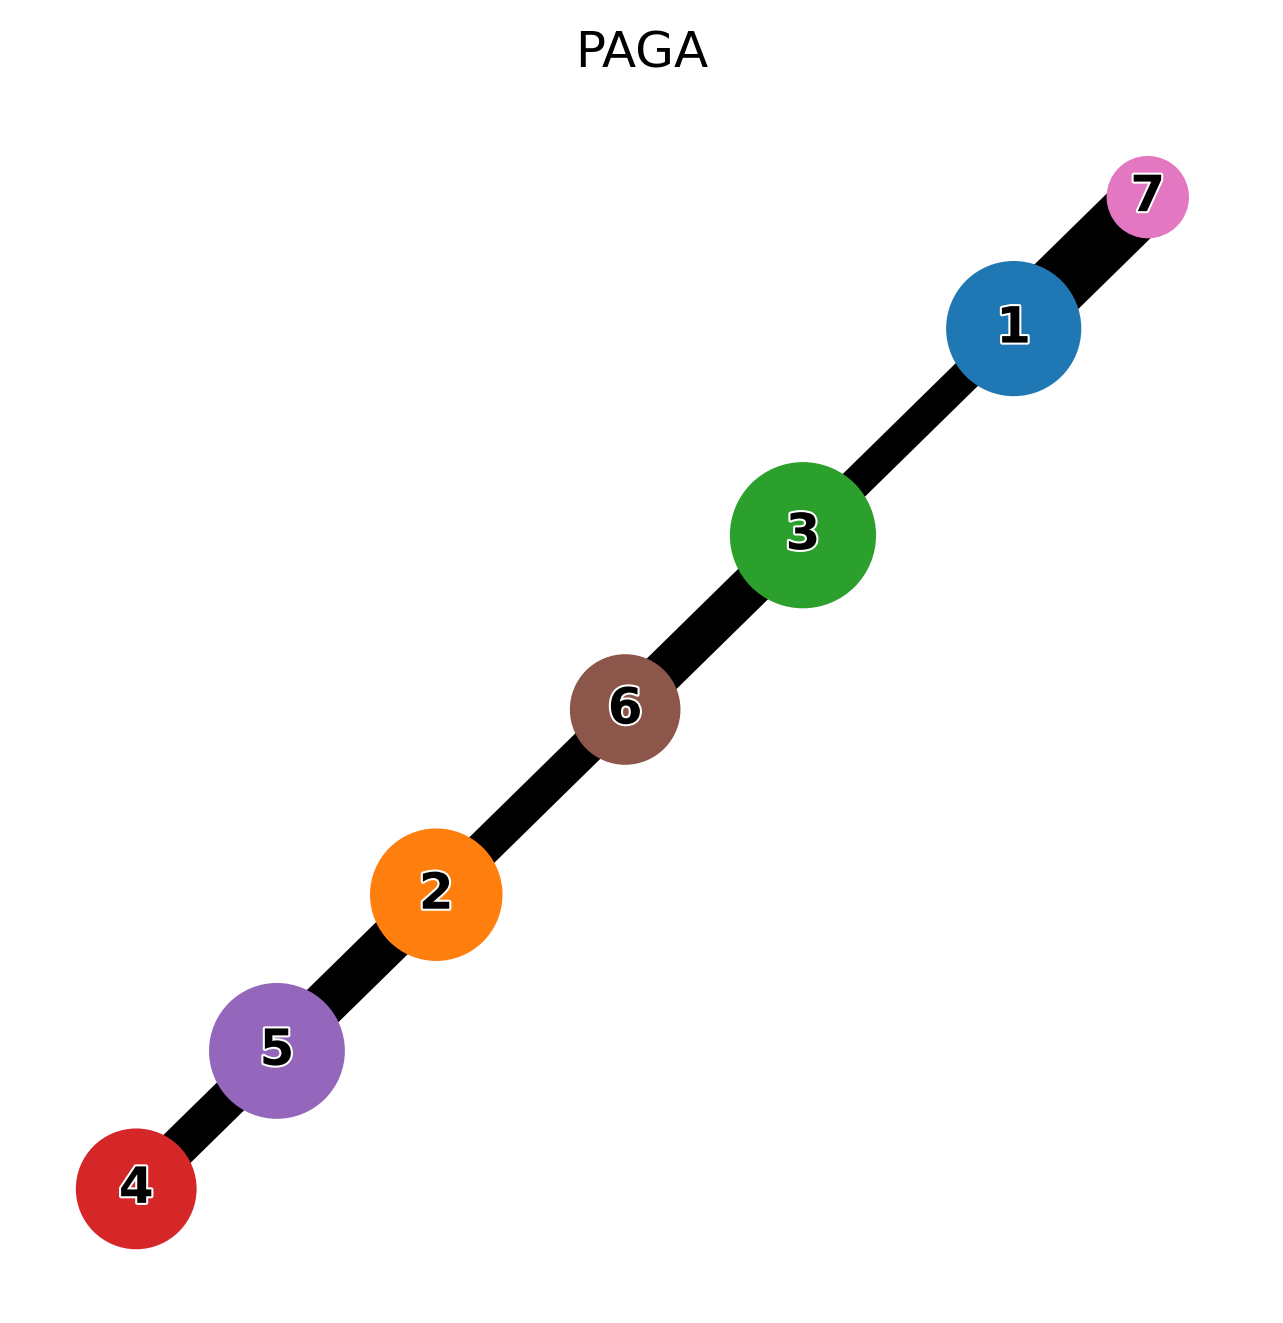

Dataset 5.Mouse_Olfactory done.


In [7]:
plot_umap(adata, 'domain',
              title=f'UMAP - {dataset}',
              save_path=os.path.join(save_dir, f'{dataset}_umap.pdf'))

plot_paga(adata, 'domain',
              save_path=os.path.join(save_dir, f'{dataset}_paga.pdf'))

print(f"Dataset {dataset} done.")
    